## 1. Import Library & Konfigurasi

In [1]:
import os                      # akses info file di sistem operasi (ukuran, tanggal)
import hashlib                 # membuat "sidik jari" digital file (MD5 / SHA-256)
import datetime                # mengubah timestamp angka menjadi tanggal terbaca
import numpy as np             # kalkulasi array angka (piksel gambar = array)
import matplotlib.pyplot as plt  # membuat grafik / menampilkan gambar
from PIL import Image, ExifTags, ImageOps  # Pillow: membuka gambar & membaca EXIF

# Ganti dengan nama file foto kamu
IMAGE_PATH = "20260929_215513.jpg"
print("Library siap. File target:", IMAGE_PATH)

Library siap. File target: 20260929_215513.jpg


**Penjelasan baris per baris:**

| Baris | Fungsi |
|---|---|
| `import os` | Modul bawaan Python untuk berinteraksi dengan file/folder. Dipakai untuk `os.path.getsize()` dll. |
| `import hashlib` | Modul bawaan untuk fungsi hash. Hash = ringkasan unik file; jika 1 byte berubah, hash berubah total. |
| `import datetime` | Modul bawaan untuk tanggal/waktu. |
| `import numpy as np` | NumPy: library angka. Gambar dibaca sebagai array 3 dimensi (tinggi × lebar × kanal). |
| `import matplotlib.pyplot as plt` | Untuk menggambar grafik dan menampilkan foto. |
| `from PIL import Image, ExifTags, ImageOps` | `Image` membuka gambar, `ExifTags` kamus penerjemah kode EXIF (angka → nama), `ImageOps` untuk koreksi orientasi. |
| `IMAGE_PATH = ...` | Variabel berisi lokasi file, supaya mudah diganti di satu tempat. |

## 2. Info File (Level Sistem Operasi)
Bagian ini membaca informasi **file**-nya, bukan isi gambarnya.

In [2]:
ukuran_byte = os.path.getsize(IMAGE_PATH)            # ukuran file dalam byte
print(f"Nama file     : {os.path.basename(IMAGE_PATH)}")
print(f"Ukuran file   : {ukuran_byte:,} byte = {ukuran_byte/1024/1024:.2f} MB")

def hitung_hash(path, algoritma):
    h = hashlib.new(algoritma)                       # buat objek hash (md5/sha256)
    with open(path, "rb") as f:                      # buka file mode biner (rb)
        for blok in iter(lambda: f.read(1024*1024), b""):  # baca per 1 MB sampai habis
            h.update(blok)                           # masukkan tiap blok ke hash
    return h.hexdigest()                             # hasil dalam format heksadesimal

print("MD5           :", hitung_hash(IMAGE_PATH, "md5"))
print("SHA-256       :", hitung_hash(IMAGE_PATH, "sha256"))

st = os.stat(IMAGE_PATH)                             # metadata file dari OS
print("Terakhir diubah (OS, bisa berbeda dari waktu foto asli jika file sudah disalin/diunduh):", datetime.datetime.fromtimestamp(st.st_mtime))

Nama file     : 20260929_215513.jpg
Ukuran file   : 11,131,359 byte = 10.62 MB
MD5           : eb0c5b06f6bf8a426a0d28ac303cda9d
SHA-256       : 947a975fe410b8d8beac7acf85af38a8271173688a615928db84fe286d7183de
Terakhir diubah (OS, bisa berbeda dari waktu foto asli jika file sudah disalin/diunduh): 2026-10-11 05:00:41.904124


**Penjelasan:**
- `os.path.getsize` → ukuran file dalam byte. Dibagi `1024*1024` untuk jadi MB.
- `hitung_hash` → fungsi pembuat sidik jari. File dibaca **per blok 1 MB** (bukan sekaligus) agar hemat memori untuk file besar. `iter(lambda: ..., b"")` artinya "terus baca sampai hasilnya kosong (akhir file)".
- **Kegunaan forensik:** hash membuktikan keaslian. Bila foto diedit/dikompres ulang, hash berubah.
- `os.stat().st_mtime` = waktu file terakhir diubah **di sistem**, bisa berbeda dengan waktu pengambilan foto di EXIF.

## 3. Info Dasar Gambar

In [3]:
img = Image.open(IMAGE_PATH)       # buka gambar (belum seluruhnya dimuat ke memori)

print("Format        :", img.format)                   # JPEG / PNG dll
print("Mode warna    :", img.mode)                     # RGB = Red, Green, Blue
print("Lebar x Tinggi:", img.size, "piksel")           # (lebar, tinggi)
lebar, tinggi = img.size
print(f"Total piksel  : {lebar*tinggi:,}  (~{lebar*tinggi/1e6:.1f} Megapiksel)")
print(f"Rasio aspek   : {lebar/tinggi:.3f}")
print("Kedalaman     : 8 bit per kanal -> 24 bit per piksel (16,7 juta warna)")
print("DPI           :", img.info.get("dpi"))

Format        : JPEG
Mode warna    : RGB
Lebar x Tinggi: (4080, 3060) piksel
Total piksel  : 12,484,800  (~12.5 Megapiksel)
Rasio aspek   : 1.333
Kedalaman     : 8 bit per kanal -> 24 bit per piksel (16,7 juta warna)
DPI           : (72.0, 72.0)


**Penjelasan:**
- `Image.open()` membuka file. `img.format`, `img.mode`, `img.size` adalah properti bawaan.
- **Mode RGB** artinya tiap piksel = 3 angka (Merah, Hijau, Biru), masing-masing 0–255.
- **Total piksel** = lebar × tinggi. Itu jumlah "titik" yang menyusun foto.
- 8 bit × 3 kanal = 24 bit → 256³ = **16.777.216** kemungkinan warna per piksel.

## 4. Metadata EXIF
EXIF adalah catatan yang ditanam kamera/HP di dalam file foto.

In [4]:
exif_raw = img.getexif()                         # ambil EXIF utama (IFD0)
exif = {}                                        # kamus: nama tag -> nilai

# Gabungkan EXIF utama + sub-blok EXIF (0x8769 = detail kamera) 
semua = dict(exif_raw)
semua.update(exif_raw.get_ifd(0x8769))           # exposure, ISO, aperture, dll

for kode, nilai in semua.items():
    nama = ExifTags.TAGS.get(kode, kode)         # terjemahkan kode angka -> nama
    if isinstance(nilai, bytes):                 # data biner (mis. MakerNote) ringkas saja
        nilai = f"<{len(nilai)} byte data biner>"
    exif[nama] = nilai

for nama, nilai in exif.items():
    print(f"{nama:28s}: {nilai}")

ImageWidth                  : 4080
ImageLength                 : 3060
GPSInfo                     : 866
ResolutionUnit              : 2
ExifOffset                  : 216
Make                        : samsung
Model                       : Galaxy A36 5G
Orientation                 : 6
DateTime                    : 2026:09:29 21:55:18
YCbCrPositioning            : 1
XResolution                 : 72.0
YResolution                 : 72.0
ExifVersion                 : <4 byte data biner>
ComponentsConfiguration     : <4 byte data biner>
ShutterSpeedValue           : 6.643
DateTimeOriginal            : 2026:09:29 21:55:18
DateTimeDigitized           : 2026:09:29 21:55:18
ApertureValue               : 1.69
BrightnessValue             : -0.95
ExposureBiasValue           : 0.0
MaxApertureValue            : 1.69
MeteringMode                : 2
LightSource                 : 21
Flash                       : 9
FocalLength                 : 4.69
ColorSpace                  : 1
ExifImageWidth          

**Penjelasan:**
- `getexif()` mengembalikan EXIF dalam bentuk kode angka (mis. `271` = Make).
- Detail kamera (ISO, shutter, aperture) disimpan di *sub-blok* alamat `0x8769`, maka kita gabungkan dengan `.update()`.
- `ExifTags.TAGS` adalah kamus penerjemah: `271 → "Make"`, `272 → "Model"`, dst.
- Data bertipe `bytes` (misalnya *MakerNote* milik pabrikan) tidak bisa dibaca manusia, jadi hanya ditampilkan ukurannya.

### 4b. Ringkasan EXIF yang Mudah Dibaca

In [5]:
def ambil(k, default="(tidak ada)"):
    return exif.get(k, default)                  # ambil nilai, jika tak ada pakai default

print("📱 PERANGKAT")
print("  Merk / Model     :", ambil("Make"), "/", ambil("Model"))
print("\n🕒 WAKTU")
print("  Waktu foto       :", ambil("DateTimeOriginal"))
print("  Zona waktu       :", ambil("OffsetTimeOriginal"), "(+07:00 = WIB)")
print("\n⚙️ PENGATURAN KAMERA")
et = ambil("ExposureTime", 0)
print(f"  Shutter speed    : {et} detik  (~1/{round(1/float(et)) if et else '?'} s)")
print("  Aperture (f/)    : f/", ambil("FNumber"))
print("  ISO              :", ambil("ISOSpeedRatings"))
print("  Focal length     :", ambil("FocalLength"), "mm  (setara", ambil("FocalLengthIn35mmFilm"), "mm di kamera full-frame)")
print("  Brightness value :", ambil("BrightnessValue"), "(negatif = adegan gelap)")
print("  Flash (kode)     :", ambil("Flash"), "->", "flash menyala" if int(ambil("Flash", 0)) & 1 else "flash tidak menyala")
print("  Orientasi (kode) :", ambil("Orientation"), "(6 = HP dipegang vertikal, diputar 90°)")

print("\n📍 GPS")
gps = exif_raw.get_ifd(0x8825)                   # blok GPS
print("  Data GPS         :", dict(gps) if gps else "KOSONG -> lokasi tidak disimpan/dihapus")

📱 PERANGKAT
  Merk / Model     : samsung / Galaxy A36 5G

🕒 WAKTU
  Waktu foto       : 2026:09:29 21:55:18
  Zona waktu       : +07:00 (+07:00 = WIB)

⚙️ PENGATURAN KAMERA
  Shutter speed    : 0.01 detik  (~1/100 s)
  Aperture (f/)    : f/ 1.8
  ISO              : 125
  Focal length     : 4.69 mm  (setara 25 mm di kamera full-frame)
  Brightness value : -0.95 (negatif = adegan gelap)
  Flash (kode)     : 9 -> flash menyala
  Orientasi (kode) : 6 (6 = HP dipegang vertikal, diputar 90°)

📍 GPS
  Data GPS         : KOSONG -> lokasi tidak disimpan/dihapus


**Penjelasan:**
- `ambil()` fungsi kecil agar program tidak error jika sebuah tag tidak ada (`dict.get` dengan nilai default).
- **Shutter `0.01` detik** → dihitung `1/0.01 = 1/100 detik`.
- **Flash `9`** → angka ini bitmask; bit pertama (`& 1`) bernilai 1 artinya flash **menyala**. Pada foto ini cahaya sekitar redup (BrightnessValue negatif) dan diambil malam hari, jadi flash menyala masuk akal. Nilai 9 = flash menembak (bit 0) + mode flash paksa (bit 3).
- **Orientation 6** → sensor menyimpan gambar landscape (4080×3060), tapi HP dipegang portrait; viewer memutarnya 90°.
- **GPS kosong** → pengaturan "tag lokasi" di kamera nonaktif, atau data dihapus. Dalam forensik, ketiadaan GPS juga informasi.

## 5. Gambar Sebagai Angka (Array Piksel)
Ini inti "bongkar isi" foto: komputer melihat foto hanya sebagai **tabel angka**.

In [6]:
img = ImageOps.exif_transpose(img)     # putar gambar sesuai Orientation EXIF (supaya tegak)
arr = np.array(img)                    # ubah gambar -> array NumPy

print("Tipe data      :", arr.dtype)    # uint8 = bilangan bulat 0..255
print("Bentuk (shape) :", arr.shape)    # (tinggi, lebar, 3 kanal)
print("Jumlah elemen  :", f"{arr.size:,}", "angka")
print("Memori array   :", f"{arr.nbytes/1024/1024:.1f} MB (tidak terkompres)")

print("\nPiksel kiri-atas [0,0] (R,G,B):", arr[0, 0])
print("Piksel tengah (R,G,B)         :", arr[arr.shape[0]//2, arr.shape[1]//2])

print("\nBlok 3x3 kanal Merah di tengah gambar:")
t, l = arr.shape[0]//2, arr.shape[1]//2
print(arr[t:t+3, l:l+3, 0])

Tipe data      : uint8
Bentuk (shape) : (4080, 3060, 3)
Jumlah elemen  : 37,454,400 angka
Memori array   : 35.7 MB (tidak terkompres)

Piksel kiri-atas [0,0] (R,G,B): [101  95  79]
Piksel tengah (R,G,B)         : [ 21  55 119]

Blok 3x3 kanal Merah di tengah gambar:
[[21 35 42]
 [21 28 19]
 [21 15  8]]


**Penjelasan:**
- `ImageOps.exif_transpose` membaca tag Orientation dan memutar gambar agar tampil seperti yang kita lihat di galeri. Setelah ini `shape` menjadi **(4080, 3060, 3)** (portrait).
- `np.array(img)` → gambar jadi array 3 dimensi: `arr[baris, kolom, kanal]`.
- `dtype=uint8` → tiap angka 0–255 (0 = gelap/tidak ada warna, 255 = paling terang).
- `arr[0,0]` → piksel pojok kiri atas, hasilnya 3 angka `[R, G, B]`.
- `arr[t:t+3, l:l+3, 0]` → *slicing*: ambil 3 baris × 3 kolom, hanya kanal ke-0 (Merah).

## 6. Statistik Tiap Kanal Warna

In [7]:
nama_kanal = ["Merah (R)", "Hijau (G)", "Biru (B)"]
print(f"{'Kanal':10s} {'Min':>5s} {'Max':>5s} {'Rata2':>8s} {'Median':>8s} {'StdDev':>8s}")
for i, nama in enumerate(nama_kanal):
    k = arr[:, :, i]                                   # ambil satu kanal saja
    print(f"{nama:10s} {k.min():5d} {k.max():5d} {k.mean():8.2f} {np.median(k):8.1f} {k.std():8.2f}")

print("\nRata-rata seluruh piksel:", arr.mean().round(2))
print("Jumlah piksel hitam murni (0,0,0)      :", int((arr.sum(axis=2) == 0).sum()))
print("Jumlah piksel putih murni (255,255,255):", int((arr.min(axis=2) == 255).sum()))

Kanal        Min   Max    Rata2   Median   StdDev
Merah (R)      0   255   121.68    130.0    50.58


Hijau (G)      0   255   123.14    127.0    49.14
Biru (B)       0   255   120.54    125.0    47.86

Rata-rata seluruh piksel: 121.79


Jumlah piksel hitam murni (0,0,0)      : 25683


Jumlah piksel putih murni (255,255,255): 12


**Penjelasan:**
- `arr[:, :, i]` → ambil semua baris & kolom, hanya kanal ke-`i`.
- **Min/Max** = nilai terendah/tertinggi; **Rata-rata** = tingkat kecerahan kanal; **Median** = nilai tengah; **StdDev** = seberapa bervariasi (kontras).
- `arr.sum(axis=2) == 0` → jumlahkan R+G+B per piksel; jika 0, piksel hitam total. `.sum()` pada array boolean menghitung jumlah `True`.
- Jika rata-rata R > G > B, foto cenderung hangat (kekuningan/kemerahan). Jika ketiganya hampir sama (seperti pada foto ini), keseimbangan warna netral, wajar karena flash berwarna putih.

## 7. Visualisasi: Foto & Histogram

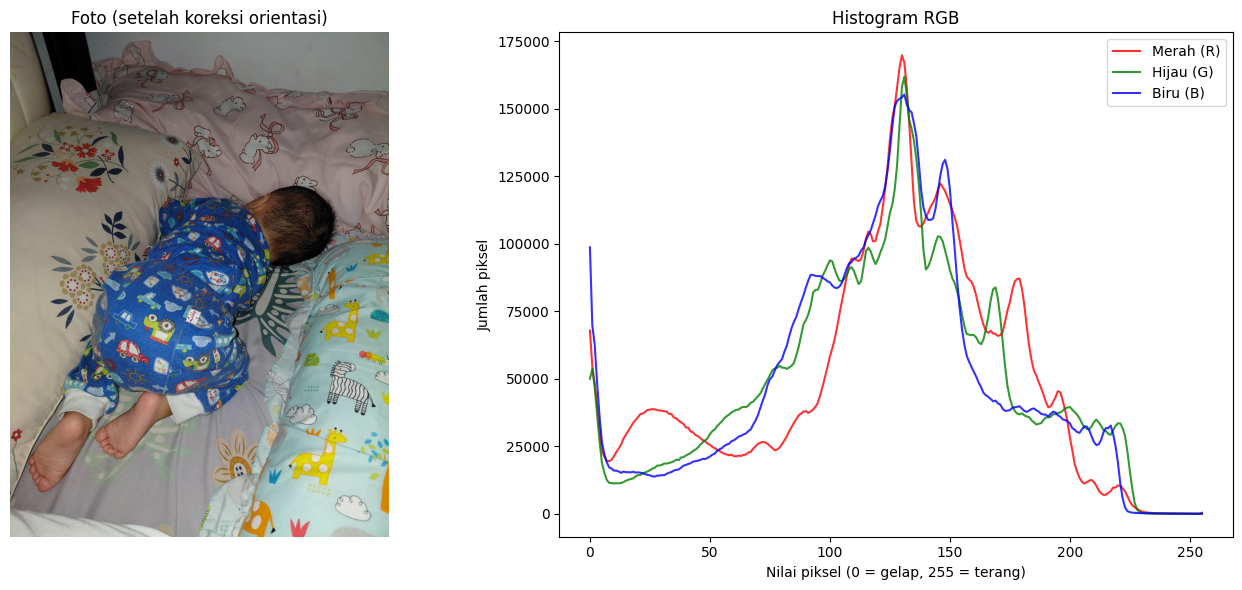

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(14, 6))           # 1 baris, 2 panel

ax[0].imshow(img)                                      # tampilkan foto
ax[0].set_title("Foto (setelah koreksi orientasi)")
ax[0].axis("off")                                      # sembunyikan sumbu

warna = ["red", "green", "blue"]
for i, w in enumerate(warna):
    hist, _ = np.histogram(arr[:, :, i], bins=256, range=(0, 255))  # hitung sebaran nilai
    ax[1].plot(hist, color=w, alpha=0.8, label=nama_kanal[i])
ax[1].set_title("Histogram RGB")
ax[1].set_xlabel("Nilai piksel (0 = gelap, 255 = terang)")
ax[1].set_ylabel("Jumlah piksel")
ax[1].legend()

plt.tight_layout()
plt.show()

**Penjelasan:**
- `plt.subplots(1, 2)` membuat dua panel berdampingan.
- `imshow` menampilkan array/gambar. `axis("off")` menghilangkan angka sumbu.
- `np.histogram(..., bins=256)` menghitung **berapa banyak piksel untuk setiap nilai 0–255**.
- **Cara membaca histogram:** puncak di kiri = foto gelap; di kanan = terang; menumpuk di tengah = kontras rendah. Bandingkan dengan EXIF: `BrightnessValue` negatif berarti cahaya sekitar redup (foto jam 21.55 malam), tetapi **flash menyala**, sehingga histogram tampak seimbang di kecerahan sedang. Tanpa flash, puncak histogram akan menumpuk di kiri (gelap).

## 8. Analisis Lanjutan: Kecerahan, Warna Dominan, Ketajaman

In [9]:
# --- 8a. Kecerahan (luminans persepsi manusia) ---
gray = 0.299*arr[:,:,0] + 0.587*arr[:,:,1] + 0.114*arr[:,:,2]   # rumus konversi ke grayscale
print(f"Kecerahan rata-rata: {gray.mean():.1f} / 255  ({gray.mean()/255*100:.1f}%)")
kategori = "GELAP" if gray.mean() < 85 else "SEDANG" if gray.mean() < 170 else "TERANG"
print("Kategori kecerahan :", kategori)

# --- 8b. Warna dominan (kuantisasi sederhana) ---
kecil = img.resize((200, 200))                         # kecilkan agar cepat
q = (np.array(kecil) // 64).reshape(-1, 3)             # bagi 4 level per kanal (0..3)
nilai, jumlah = np.unique(q, axis=0, return_counts=True)  # hitung kombinasi unik
urut = np.argsort(-jumlah)[:5]                         # 5 terbanyak
print("\n5 warna dominan:")
for j in urut:
    rgb = nilai[j]*64 + 32                             # kembalikan ke skala 0-255 (titik tengah)
    print(f"  RGB{tuple(int(x) for x in rgb)}  -> {jumlah[j]/len(q)*100:.1f}% dari gambar")

# --- 8c. Ketajaman (variansi Laplacian, tanpa OpenCV) ---
g = gray[::4, ::4]                                     # ambil tiap 4 piksel biar ringan
lap = (-4*g[1:-1,1:-1] + g[:-2,1:-1] + g[2:,1:-1] + g[1:-1,:-2] + g[1:-1,2:])
print(f"\nSkor ketajaman (variansi Laplacian): {lap.var():.1f}")
print("Makin besar = makin tajam; sangat kecil = blur / kurang detail")

Kecerahan rata-rata: 122.4 / 255  (48.0%)
Kategori kecerahan : SEDANG

5 warna dominan:
  RGB(160, 160, 160)  -> 29.4% dari gambar
  RGB(96, 96, 96)  -> 25.2% dari gambar
  RGB(160, 96, 96)  -> 7.1% dari gambar
  RGB(32, 32, 32)  -> 4.7% dari gambar
  RGB(160, 160, 96)  -> 4.6% dari gambar

Skor ketajaman (variansi Laplacian): 2647.3
Makin besar = makin tajam; sangat kecil = blur / kurang detail


**Penjelasan:**
- **8a.** Mata manusia lebih peka pada hijau, maka bobot grayscale `0.299 R + 0.587 G + 0.114 B` (standar ITU-R BT.601).
- **8b.** Warna dominan: gambar dikecilkan → tiap kanal dibagi 64 (jadi 4 level) → dihitung kombinasi warna terbanyak dengan `np.unique(..., return_counts=True)` → dikembalikan ke skala 0–255.
- **8c.** *Laplacian* mengukur perubahan tajam antar piksel tetangga (tepi). **Variansi**-nya jadi skor ketajaman: foto blur hampir tidak punya tepi tajam, sehingga variansinya kecil. `g[::4, ::4]` = ambil tiap piksel ke-4 agar komputasi ringan.

## 9. Ringkasan Otomatis (Laporan Forensik)

In [10]:
laporan = {
    "File": os.path.basename(IMAGE_PATH),
    "Ukuran file (MB)": round(ukuran_byte/1024/1024, 2),
    "Resolusi (setelah rotasi)": f"{arr.shape[1]} x {arr.shape[0]}",
    "Perangkat": f"{ambil('Make')} {ambil('Model')}",
    "Waktu pengambilan": f"{ambil('DateTimeOriginal')} ({ambil('OffsetTimeOriginal')})",
    "ISO / f / shutter": f"{ambil('ISOSpeedRatings')} / f{ambil('FNumber')} / 1/{round(1/float(ambil('ExposureTime',1)))}s",
    "GPS": "ada" if gps else "tidak ada",
    "Rata-rata RGB": tuple(float(x) for x in arr.reshape(-1,3).mean(axis=0).round(1)),
    "Kecerahan": f"{gray.mean():.1f}/255 ({kategori})",
}
for k, v in laporan.items():
    print(f"{k:28s}: {v}")

File                        : 20260929_215513.jpg
Ukuran file (MB)            : 10.62
Resolusi (setelah rotasi)   : 3060 x 4080
Perangkat                   : samsung Galaxy A36 5G
Waktu pengambilan           : 2026:09:29 21:55:18 (+07:00)
ISO / f / shutter           : 125 / f1.8 / 1/100s
GPS                         : tidak ada
Rata-rata RGB               : (121.7, 123.1, 120.5)
Kecerahan                   : 122.4/255 (SEDANG)
